# Module 04: Forward Pass, Activations, Loss Functions, and Output Layers

This module explains what happens when a neural network makes predictions. The forward pass creates intermediate activations, logits, probabilities, and loss values. The output layer and loss must match the task.


## Module outline

* **Step 1: Forward Pass Foundations**
  * Forward pass, layer computation, batch input, intermediate activation, prediction output, cached value.
* **Step 2: Affine Layer $XW+b$**
  * Matrix multiplication, weight matrix, bias vector, dense layer, parameter count, shape checking.
* **Step 3: Logits and Scores**
  * Raw score, binary logit, multiclass logits, logits vs probabilities, confidence, argmax.
* **Step 4: Activation Functions**
  * Identity, sigmoid, tanh, ReLU, Leaky ReLU, ELU, GELU, Swish, saturation, dead ReLU, activation choice.
* **Step 5: Softmax Outputs**
  * Softmax formula, stable softmax, class probabilities, temperature, top class, probability calibration preview.
* **Step 6: Regression Losses**
  * Residual, MSE, RMSE, MAE, Huber, outlier sensitivity, target scale.
* **Step 7: Classification Losses**
  * Binary cross-entropy, categorical cross-entropy, sparse labels, one-hot labels, negative log likelihood.
* **Step 8: Output Layer by Task**
  * Binary classification, multiclass classification, multilabel classification, regression, count prediction.
* **Step 9: Loss Surface Intuition**
  * Parameter space, loss curve, convex intuition, non-convex intuition, plateau, local minimum, sharp vs flat region.
* **Step 10: Common Output/Loss Mistakes**
  * Sigmoid with multiclass, softmax with multilabel, double softmax, MSE for classification, unscaled target.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import make_moons, make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.metrics import accuracy_score, classification_report, mean_absolute_error, mean_squared_error

plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['font.size'] = 10
rng = np.random.default_rng(42)


## Step 1: Forward Pass Foundations

The forward pass is the calculation that turns input data into predictions. Training first runs a forward pass, then computes loss, then uses backpropagation to update parameters.


### 1.1 Forward pass

**Definition:** The sequence of calculations from input to model output.

**Where it is used:** Every prediction and every training step.

**Why it matters:** Without it there is no prediction or loss to optimize.

**Simple example:** Input table -> hidden activations -> logits -> probabilities.

**Common mistake:** Thinking forward pass means training; training also needs loss and backward pass.


### 1.2 Batch input

**Definition:** A group of examples processed together.

**Where it is used:** Modern GPU/CPU training and inference.

**Why it matters:** It makes computation efficient and stabilizes gradients.

**Simple example:** A batch shape (32, 100) means 32 examples with 100 features.

**Common mistake:** Confusing batch size with feature count.


### 1.3 Intermediate activation

**Definition:** A value produced inside the network before final output.

**Where it is used:** Backpropagation and model interpretation.

**Why it matters:** Gradients often need these cached values.

**Simple example:** ReLU output from layer 1 is an intermediate activation.

**Common mistake:** Deleting cached values before backward pass.


### 1.4 Prediction output

**Definition:** The final model value used for the task.

**Where it is used:** Inference and loss calculation.

**Why it matters:** Its meaning changes by task.

**Simple example:** A probability for classification or a number for regression.

**Common mistake:** Using the same output activation for all tasks.


In [2]:
X=rng.normal(size=(4,3))
W1=rng.normal(size=(3,5)); b1=np.zeros(5)
W2=rng.normal(size=(5,2)); b2=np.zeros(2)
Z1=X@W1+b1; A1=np.maximum(0,Z1); logits=A1@W2+b2
print('X',X.shape,'Z1',Z1.shape,'A1',A1.shape,'logits',logits.shape)


X (4, 3) Z1 (4, 5) A1 (4, 5) logits (4, 2)


## Step 2: Affine Layer $XW+b$

A dense layer first performs an affine transformation. The weight matrix mixes features, and the bias shifts each output unit.


### 2.1 Weight matrix

**Definition:** A trainable matrix that maps input features to output units.

**Where it is used:** Dense layers and output heads.

**Why it matters:** It decides how each input contributes to each output.

**Simple example:** Shape (6,4) maps 6 input features to 4 output units.

**Common mistake:** Transposing it accidentally and causing shape errors.


### 2.2 Bias vector

**Definition:** A trainable vector added to each row after matrix multiplication.

**Where it is used:** Dense and convolution layers.

**Why it matters:** It lets each output unit shift independently.

**Simple example:** For 4 output units, bias shape is (4,).

**Common mistake:** Using one bias per sample instead of per unit.


### 2.3 Dense layer

**Definition:** A layer where each input feature connects to each output unit.

**Where it is used:** MLPs and classifier/regression heads.

**Why it matters:** It can learn arbitrary feature combinations.

**Simple example:** Input width 6 and output width 4 has 6*4+4 parameters.

**Common mistake:** Using dense layers directly on very high-dimensional raw inputs without checking size.


### 2.4 Parameter count

**Definition:** Number of trainable values.

**Where it is used:** Memory, compute, and overfitting analysis.

**Why it matters:** It tells how large the model is.

**Simple example:** A 6-to-4 dense layer has 28 parameters.

**Common mistake:** Ignoring bias parameters.


### 2.5 Shape checking

**Definition:** Verifying dimensions before operations.

**Where it is used:** Debugging every neural network.

**Why it matters:** Most layer bugs are shape bugs.

**Simple example:** (batch,6)@(6,4)->(batch,4).

**Common mistake:** Only checking total element count instead of axis meaning.


In [3]:
batch,in_features,out_units=8,6,4
X=rng.normal(size=(batch,in_features)); W=rng.normal(size=(in_features,out_units)); b=np.zeros(out_units)
Z=X@W+b
print('Z shape:',Z.shape,'parameter count:',W.size+b.size)


Z shape: (8, 4) parameter count: 28


## Step 3: Logits and Scores

Logits are raw model scores before probability conversion. They can be negative or greater than 1, and they do not need to sum to 1.


### 3.1 Raw score

**Definition:** Unnormalized output from the final linear layer.

**Where it is used:** Classification heads before sigmoid or softmax.

**Why it matters:** It preserves information before probability conversion.

**Simple example:** Logits [-2, 0.5, 3] favor the third class.

**Common mistake:** Calling raw scores probabilities.


### 3.2 Binary logit

**Definition:** One score converted to class-1 probability by sigmoid.

**Where it is used:** Binary classification and multilabel classification.

**Why it matters:** One number is enough for a yes/no probability.

**Simple example:** Logit 0 gives probability 0.5.

**Common mistake:** Using two-output softmax when one sigmoid output is simpler.


### 3.3 Multiclass logits

**Definition:** One raw score per class.

**Where it is used:** Single-label multiclass classification.

**Why it matters:** Softmax compares all class scores together.

**Simple example:** Digit classifier has 10 logits.

**Common mistake:** Using sigmoid for mutually exclusive classes.


### 3.4 Argmax

**Definition:** Index of the largest score or probability.

**Where it is used:** Choosing predicted class.

**Why it matters:** It turns scores into a class label.

**Simple example:** If class probabilities are [0.1,0.8,0.1], argmax is 1.

**Common mistake:** Using argmax before computing cross-entropy during training.


In [4]:
logits=np.array([[-2.0,.5,3.0]])
e=np.exp(logits-logits.max(axis=1,keepdims=True)); p=e/e.sum(axis=1,keepdims=True)
print('logits:',logits)
print('softmax probabilities:',np.round(p,4),'sum:',p.sum())
print('argmax class:',p.argmax(axis=1)[0])


logits: [[-2.   0.5  3. ]]
softmax probabilities: [[0.0062 0.0754 0.9184]] sum: 0.9999999999999999
argmax class: 2


## Step 4: Activation Functions

Activation functions control nonlinearity, output range, and gradient behavior.


### 4.1 Identity activation

**Definition:** Returns the input unchanged.

**Where it is used:** Regression output layers.

**Why it matters:** It allows unrestricted numeric predictions.

**Simple example:** House price output should not be squeezed to 0-1 unless target is scaled that way.

**Common mistake:** Using sigmoid for regression when target is not bounded.


### 4.2 Sigmoid

**Definition:** Maps any real number to 0-1.

**Where it is used:** Binary and multilabel outputs.

**Why it matters:** It represents independent probabilities.

**Simple example:** Spam probability 0.92.

**Common mistake:** Using it in deep hidden layers can cause saturation.


### 4.3 Tanh

**Definition:** Maps values to -1 to 1.

**Where it is used:** Some recurrent networks and bounded hidden states.

**Why it matters:** It is zero-centered compared with sigmoid.

**Simple example:** A hidden state can be negative or positive.

**Common mistake:** Forgetting it still saturates.


### 4.4 ReLU

**Definition:** Returns max(0,z).

**Where it is used:** Default hidden activation in many MLPs/CNNs.

**Why it matters:** It is simple and keeps strong gradients for positive values.

**Simple example:** Score -2 becomes 0, score 3 stays 3.

**Common mistake:** Dead ReLU when units stay negative.


### 4.5 Leaky ReLU

**Definition:** Like ReLU but keeps a small negative slope.

**Where it is used:** Hidden layers where dead ReLU is a concern.

**Why it matters:** It allows some gradient for negative inputs.

**Simple example:** -2 becomes -0.2 if slope is 0.1.

**Common mistake:** Assuming it fixes every training problem.


### 4.6 GELU

**Definition:** Smooth activation often used in transformers.

**Where it is used:** Transformer feed-forward networks.

**Why it matters:** It gates values smoothly based on magnitude.

**Simple example:** Small negative values are reduced but not sharply zeroed.

**Common mistake:** Replacing activations blindly without tuning.


### 4.7 Saturation

**Definition:** Region where derivative becomes tiny.

**Where it is used:** Sigmoid/tanh hidden layers.

**Why it matters:** It slows or blocks learning.

**Simple example:** Sigmoid at z=10 is almost flat.

**Common mistake:** Initializing weights so large that all activations saturate.


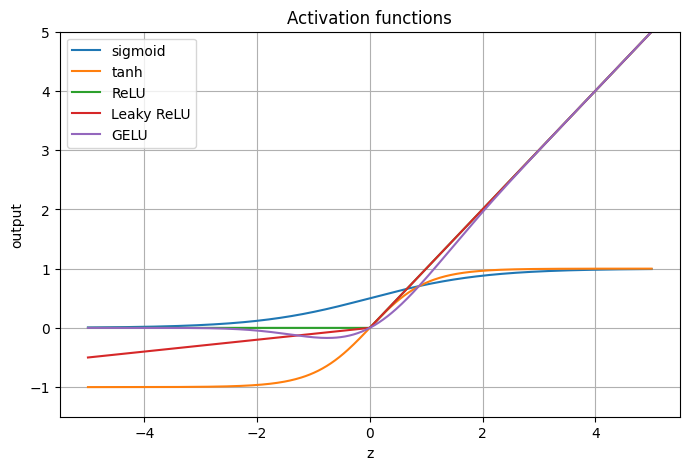

In [5]:
z=np.linspace(-5,5,400)
sig=1/(1+np.exp(-z)); tanh=np.tanh(z); relu=np.maximum(0,z); leaky=np.where(z>0,z,.1*z)
gelu=.5*z*(1+np.tanh(np.sqrt(2/np.pi)*(z+.044715*z**3)))
for arr,name in [(sig,'sigmoid'),(tanh,'tanh'),(relu,'ReLU'),(leaky,'Leaky ReLU'),(gelu,'GELU')]:
    plt.plot(z,arr,label=name)
plt.title('Activation functions'); plt.xlabel('z'); plt.ylabel('output'); plt.ylim(-1.5,5); plt.legend();


## Step 5: Softmax Outputs

Softmax converts multiclass logits into probabilities that sum to 1. It is used when exactly one class should be selected.


### 5.1 Softmax

**Definition:** Exponentiates logits and divides by their sum.

**Where it is used:** Multiclass output layers.

**Why it matters:** It turns competing class scores into probabilities.

**Simple example:** [2,1,.1] becomes probabilities where class 0 is largest.

**Common mistake:** Using softmax for multilabel tasks.


### 5.2 Stable softmax

**Definition:** Softmax after subtracting the maximum logit.

**Where it is used:** Any real implementation.

**Why it matters:** It prevents overflow from very large exponentials.

**Simple example:** Use exp(z-max(z)).

**Common mistake:** Computing exp(1000) directly.


### 5.3 Temperature

**Definition:** A divisor that controls probability sharpness.

**Where it is used:** Calibration, distillation, sampling.

**Why it matters:** Lower temperature sharpens; higher temperature softens.

**Simple example:** Temperature 2 spreads probability more evenly.

**Common mistake:** Treating temperature as training accuracy improvement automatically.


### 5.4 Calibration preview

**Definition:** How well predicted probabilities match real correctness frequency.

**Where it is used:** Model reliability and deployment.

**Why it matters:** A model can be accurate but overconfident.

**Simple example:** If predictions at 90% confidence are correct 70% of time, it is miscalibrated.

**Common mistake:** Thinking probability confidence always equals truth.


In [6]:
def softmax(z,temp=1.0):
    z=z/temp; z=z-z.max(axis=1,keepdims=True); e=np.exp(z); return e/e.sum(axis=1,keepdims=True)
logits=np.array([[2.0,1.0,.1]])
for t in [.5,1,2]:
    print('temperature',t, np.round(softmax(logits,t),4))


temperature 0.5 [[0.8638 0.1169 0.0193]]
temperature 1 [[0.659  0.2424 0.0986]]
temperature 2 [[0.5017 0.3043 0.194 ]]


## Step 6: Regression Losses

Regression losses compare predicted numbers with true numbers.


### 6.1 Residual

**Definition:** Difference between true and predicted value.

**Where it is used:** Regression metrics and losses.

**Why it matters:** It is the raw error before summarizing.

**Simple example:** True 120, predicted 110 gives residual 10.

**Common mistake:** Ignoring error direction when direction matters.


### 6.2 MSE

**Definition:** Mean squared error.

**Where it is used:** Regression training when large errors should be punished strongly.

**Why it matters:** Squaring makes large errors dominate.

**Simple example:** Errors [1,10] become squared [1,100].

**Common mistake:** Using it with large outliers without checking impact.


### 6.3 RMSE

**Definition:** Square root of MSE.

**Where it is used:** Regression reporting.

**Why it matters:** It returns error to target units.

**Simple example:** RMSE of 5 dollars is interpretable as dollars.

**Common mistake:** Optimizing only RMSE without checking MAE/outliers.


### 6.4 MAE

**Definition:** Mean absolute error.

**Where it is used:** Robust regression reporting/training.

**Why it matters:** It is easier to interpret and less outlier-sensitive.

**Simple example:** Average absolute salary error is 3000.

**Common mistake:** Forgetting MAE gradient is less smooth at zero.


### 6.5 Huber loss

**Definition:** MSE for small errors, MAE-like for large errors.

**Where it is used:** Regression with moderate outliers.

**Why it matters:** It balances smooth gradients and robustness.

**Simple example:** Small residual 2 is squared; large residual 100 is linear-ish.

**Common mistake:** Choosing delta without considering target scale.


In [7]:
y_true=np.array([100,120,130,140,1000.])
y_pred=np.array([110,118,125,150,140.])
res=y_true-y_pred
mse=np.mean(res**2); rmse=np.sqrt(mse); mae=np.mean(np.abs(res))
delta=50; huber=np.mean(np.where(np.abs(res)<=delta,.5*res**2,delta*(np.abs(res)-.5*delta)))
print('residuals:',res)
print('MSE',round(mse,2),'RMSE',round(rmse,2),'MAE',round(mae,2),'Huber',round(huber,2))


residuals: [-10.   2.   5. -10. 860.]
MSE 147965.8 RMSE 384.66 MAE 177.4 Huber 8372.9


## Step 7: Classification Losses

Classification losses become small when the model gives high probability to the correct class.


### 7.1 Binary cross-entropy

**Definition:** Loss for one yes/no target.

**Where it is used:** Binary and multilabel classification.

**Why it matters:** It heavily punishes confident wrong probabilities.

**Simple example:** If true class is 1 and p=0.01, loss is high.

**Common mistake:** Passing hard class labels as probabilities.


### 7.2 Categorical cross-entropy

**Definition:** Loss for one-hot multiclass targets.

**Where it is used:** Single-label multiclass classification.

**Why it matters:** It is negative log probability of the correct class.

**Simple example:** If correct class probability is .9, loss is low.

**Common mistake:** Using it with integer labels when the function expects one-hot labels.


### 7.3 Sparse label

**Definition:** Integer class label instead of one-hot vector.

**Where it is used:** Sparse cross-entropy APIs.

**Why it matters:** It saves memory for many classes.

**Simple example:** Class 7 instead of vector length 10000.

**Common mistake:** Using sparse and one-hot loss variants interchangeably.


### 7.4 Negative log likelihood

**Definition:** The loss value $-\log(p_{correct})$.

**Where it is used:** Cross-entropy interpretation.

**Why it matters:** It rewards high probability on correct class.

**Simple example:** p=.9 gives .105; p=.01 gives 4.605.

**Common mistake:** Thinking loss increases linearly as probability decreases.


In [8]:
def bce(y,p):
    p=np.clip(p,1e-12,1-1e-12); return -(y*np.log(p)+(1-y)*np.log(1-p))
probs=np.array([.01,.1,.5,.9,.99])
display(pd.DataFrame({'p_when_y=1':probs,'BCE':bce(1,probs)}))
p_multi=np.array([[.05,.90,.05],[.40,.35,.25]])
true=np.array([1,1])
print('cross entropy:', -np.log(p_multi[np.arange(len(true)),true]))


,p_when_y=1,BCE
0,0.01,4.605170
1,0.10,2.302585
2,0.50,0.693147
3,0.90,0.105361
4,0.99,0.010050


cross entropy: [0.10536052 1.04982212]


## Step 8: Output Layer by Task

| Task | Output units | Activation | Common loss |
|---|---:|---|---|
| Binary classification | 1 | Sigmoid | Binary cross-entropy |
| Multiclass classification | number of classes | Softmax | Sparse/categorical cross-entropy |
| Multilabel classification | number of labels | Sigmoid per label | Binary cross-entropy |
| Regression | target dimensions | Linear | MSE, MAE, Huber |
| Count prediction | 1 | Linear or positive transform | Poisson or regression loss |


## Step 9: Loss Surface Intuition

A loss surface shows loss for different parameter values. Optimizers move through this surface using gradients.


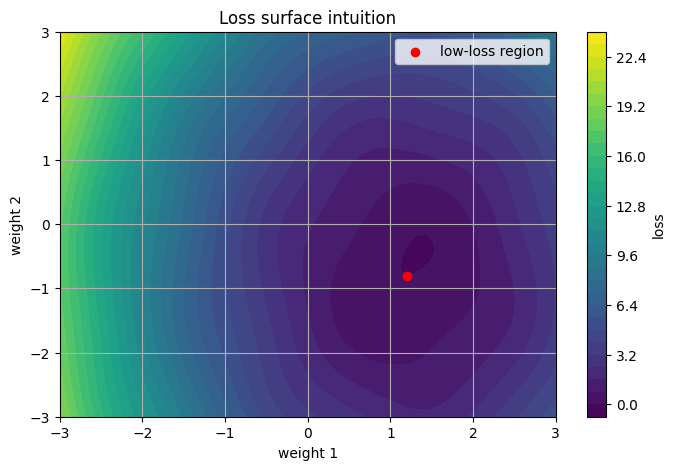

In [9]:
w1=np.linspace(-3,3,120); w2=np.linspace(-3,3,120)
W1,W2=np.meshgrid(w1,w2)
Loss=(W1-1.2)**2+.4*(W2+.8)**2+.25*np.sin(3*W1)*np.cos(2*W2)
plt.contourf(W1,W2,Loss,levels=30,cmap='viridis'); plt.colorbar(label='loss')
plt.scatter([1.2],[-.8],color='red',label='low-loss region')
plt.title('Loss surface intuition'); plt.xlabel('weight 1'); plt.ylabel('weight 2'); plt.legend();


## Step 10: Common Output/Loss Mistakes

* **Softmax for multilabel:** multilabel needs independent sigmoid probabilities.
* **Sigmoid for single-label multiclass:** softmax is usually correct because classes compete.
* **Double softmax:** many framework losses expect logits and apply stable softmax internally.
* **MSE for classification:** cross-entropy usually gives better probability learning.
* **Unscaled regression target:** very large targets can create unstable losses and gradients.
* **Treating logits as probabilities:** logits are raw scores.

## Module 04 Summary

The forward pass creates activations, logits, probabilities, and losses. Activation functions add nonlinearity. The output layer and loss function must match the task type; otherwise, training signals become confusing or wrong.
